# 로보택시 도시 진입·차량 배분 toy 실험 (ER-SAA / ER-DRO, CVaR형)

문서(2단계 ER-DRO 모형, 수요 함수 f 절)의 식과 1:1로 대응. **모든 셀이 위에서 아래로 한 번씩 실행되는 평면 구조**이며, 변수는 전부 전역이라 어느 셀에서든 바로 볼 수 있다.

| 셀 | 하는 일 | 문서 식 |
|---|---|---|
| 0 | 패키지, ACS 실제 무차량 가구 비율 표, 공통 함수(σ, logit) | — |
| 1 | 후보 도시 입력 x_c, M_c, κ_c, q̄_c, F0 | 표기 |
| 2 | 참 모형 설정, 평가 시나리오 D_eval, 총 차량 Q | (sigmoid) |
| 3 | 훈련 데이터 생성 함수 → 로짓 OLS(f 학습) 함수 → 시나리오 함수 | (ols), (resid), (scen) |
| 4 | ER-DRO MILP(통째로) 함수, L-shaped(분해) 함수, OOS 평가 함수 | (4a)–(4h), (5), (3) |
| 5 | f 학습 실행: N별로 β̂, ε̂, D_cs 를 만들어 저장 | — |
| 6 | 실험 루프 → `results` 리스트 | — |
| 7 | (선택) 통째로 vs 분해 비교 | — |
| 8 | 결과 CSV 저장, 그림 | — |

Colab: 런타임 → 모두 실행 (약 4분). 셀 7은 `RUN_COMPARE=True`로 바꿀 때만 돈다.

## 0. 패키지·실제 ACS 자료·공통 함수

```
toy_experiment.py  (v2: 실제 ACS 무차량 가구 비율 반영, c+ = 1 고정 / c- 변화)
=====================================================================
로보택시 도시 진입·차량 배분 문제의 toy 실험.

전체 흐름 (문서의 식 번호와 대응)
  [1] 후보 도시 입력            : C, x_c (ACS 실제값), M_c, kappa_c, qbar_c, F_c, Q, c+, c-
  [2] 참 모형에서 훈련 데이터 생성 : p = sigma(beta0 + beta1*x + eps)        ... 식 (sigmoid)
  [3] 로짓 OLS 회귀 -> beta_hat, 잔차 eps_hat                                  ... 식 (ols), (resid)
  [4] 시나리오 생성  p_c^s, D_c^s = M_c p_c^s                                  ... 식 (scen)
  [5] ER-DRO (CVaR형) MILP 풀기                                                ... 식 (4a)-(4h), 변형 (5)
  [6] 참 모형에서 뽑은 평가 시나리오로 out-of-sample 비용 계산
  [7] 실험 루프 (N, zeta, c-) -> 결과 표 CSV + 그림

기호 대응 (코드 변수명 = 문서 기호)
  x_c      : 도시 c의 무차량 가구 비율 (context).  ACS 2019-2023 5년 추정, 표 B08201, county 단위 실제값
  M_c      : 도시 c의 잠재 이동 기회 수 (통행/년). toy에서는 ACS 가구 수에 비례하도록 둠
  kappa_c  : 차량 1대의 연간 처리 통행 수
  qbar_c   : 도시별 차량 상한
  F_c      : 도시 진입 고정비
  Q        : 총 보유 차량 수
  c_plus   : 잉여 용량 1통행당 손실 (c+).  여기서는 1로 고정
  c_minus  : 미충족 1통행당 기회손실 (c-). {1, 5, 10} 으로 변화 -> c+:c- = 1:1, 1:5, 1:10
  zeta     : CVaR 꼬리 비율. 0이면 ER-SAA(표본평균)
  B        : (변형) 진입 가능 도시 수. None이면 F_c y_c 를 목적함수에 둔 기본 모형
  beta0, beta1, sigma_eps : 참 모형의 계수와 오차 표준편차
  N        : 훈련 관측 수 = 시나리오 수 |S|

필요 패키지: numpy, scipy (>=1.9, milp/HiGHS), matplotlib
```

In [ ]:
!pip -q install 'scipy>=1.11' matplotlib

import numpy as np
from scipy.optimize import milp, LinearConstraint, Bounds
import csv

rng = np.random.default_rng(2026)   # 난수 고정 (재현용)

In [ ]:
# 출처: U.S. Census Bureau, ACS 2019-2023 5-year, 표 B08201 (Esri Living Atlas
#       "ACS Vehicle Availability Variables - Boundaries", County layer에서 조회, 2026-10 기준).
# 값: (county 이름, GEOID, 총 가구 수 B08201_001E, 무차량 가구 비율 % B08201_calc_pctNoVehE)
# 도시 -> county 대응은 중심 county 하나로 단순화 (예: Phoenix -> Maricopa). 뉴욕은 New York County(맨해튼)만.
ACS_NO_VEHICLE = {
    # --- 현재 로보택시 운영 시장 (Waymo/Zoox/Tesla, 01_robotaxi_companies_markets.tex) ---
    "Phoenix":        ("Maricopa County, AZ",      "04013", 1697342,  5.1),
    "San Francisco":  ("San Francisco County, CA", "06075",  362650, 29.9),
    "Los Angeles":    ("Los Angeles County, CA",   "06037", 3390254,  8.7),
    "Austin":         ("Travis County, TX",        "48453",  561491,  5.8),
    "Atlanta":        ("Fulton County, GA",        "13121",  457791, 10.0),
    "Miami":          ("Miami-Dade County, FL",    "12086",  964805,  9.7),
    "Dallas":         ("Dallas County, TX",        "48113",  971690,  6.8),
    "Houston":        ("Harris County, TX",        "48201", 1728103,  6.8),
    "Nashville":      ("Davidson County, TN",      "47037",  314578,  6.6),
    "Orlando":        ("Orange County, FL",        "12095",  508907,  5.4),
    "San Antonio":    ("Bexar County, TX",         "48029",  740402,  6.3),
    "Las Vegas":      ("Clark County, NV",         "32003",  847378,  7.6),
    # --- Waymo 향후 후보 시장 ---
    "Baltimore":      ("Baltimore city, MD",       "24510",  250608, 26.6),
    "Boston":         ("Suffolk County, MA",       "25025",  322184, 31.8),
    "Charlotte":      ("Mecklenburg County, NC",   "37119",  455494,  5.7),
    "Chicago":        ("Cook County, IL",          "17031", 2084578, 18.0),
    "Denver":         ("Denver County, CO",        "08031",  329578, 10.3),
    "Detroit":        ("Wayne County, MI",         "26163",  693446, 11.8),
    "Minneapolis":    ("Hennepin County, MN",      "27053",  534573,  8.9),
    "New Orleans":    ("Orleans Parish, LA",       "22071",  155060, 17.1),
    "New York":       ("New York County, NY",      "36061",  775376, 77.7),
    "Philadelphia":   ("Philadelphia County, PA",  "42101",  669222, 27.8),
    "Pittsburgh":     ("Allegheny County, PA",     "42003",  546507, 12.5),
    "Portland":       ("Multnomah County, OR",     "41051",  347392, 12.7),
    "Sacramento":     ("Sacramento County, CA",    "06067",  568223,  6.4),
    "San Diego":      ("San Diego County, CA",     "06073", 1159822,  5.4),
    "Seattle":        ("King County, WA",          "53033",  927817, 11.0),
    "St. Louis":      ("St. Louis city, MO",       "29510",  144450, 17.9),
    "Tampa":          ("Hillsborough County, FL",  "12057",  569998,  5.8),
    "Washington DC":  ("District of Columbia",     "11001",  321556, 35.9),
}

CURRENT_MARKETS = ["Phoenix", "San Francisco", "Los Angeles", "Austin", "Atlanta", "Miami",
                   "Dallas", "Houston", "Nashville", "Orlando", "San Antonio", "Las Vegas"]
FUTURE_CANDIDATES = ["Baltimore", "Boston", "Charlotte", "Chicago", "Denver", "Detroit",
                     "Minneapolis", "New Orleans", "New York", "Philadelphia", "Pittsburgh",
                     "Portland", "Sacramento", "San Diego", "Seattle", "St. Louis", "Tampa",
                     "Washington DC"]

In [ ]:
def sigma(z):
    """시그모이드 sigma(z) = 1/(1+e^{-z}).  로짓의 역함수. 어떤 실수든 (0,1)로 보냄."""
    return 1.0 / (1.0 + np.exp(-z))


def logit(p):
    """logit(p) = ln(p/(1-p)).  (0,1)의 확률을 실수 전체로 펼침."""
    return np.log(p / (1.0 - p))

## 1. 후보 도시 입력 (x_c = ACS 실제값, M_c = 가구 수 × 10, κ_c = 8,760, q̄_c = 150, F0 = 10⁵)

In [ ]:
def make_cities(city_names, trips_per_household=10.0, qbar=150, F0=1.0e5):
    """
    후보 도시 입력을 만든다.
      x_c  : ACS 실제 무차량 가구 비율 (0~1 척도)
      M_c  : 잠재 이동 기회 = (ACS 총 가구 수) x trips_per_household (기본 10).
             비례상수 trips_per_household 는 toy용 가정 (실데이터에서는 Factors of M 의 (c) 방법으로 대체).
      kappa_c = 8,760 (24통행/일 x 365일, large case 와 동일)
      qbar_c  = qbar (도시별 상한)
      F0      : 진입 고정비의 기준값. c- = 1 일 때의 값이며, 실험에서 c- 에 비례해 키운다 (아래 main 참조) / F = F0 X c-
    """
    names = list(city_names)
    x_c = np.array([ACS_NO_VEHICLE[n][3] / 100.0 for n in names])
    households = np.array([ACS_NO_VEHICLE[n][2] for n in names], dtype=float)
    M_c = households * trips_per_household
    kappa_c = np.full(len(names), 8760.0)
    qbar_c = np.full(len(names), qbar)
    F0_c = np.full(len(names), F0)
    return names, x_c, M_c, kappa_c, qbar_c, F0_c


# ---- 실행: 후보 도시 = Waymo 향후 후보 18개 ----
names, x_c, M_c, kappa_c, qbar_c, F0_c = make_cities(FUTURE_CANDIDATES)
nC = len(names)
print(f"후보 도시 {nC}개. x_c 범위 = {x_c.min():.3f} ~ {x_c.max():.3f}")
for n, x, M in zip(names, x_c, M_c):
    print(f"  {n:14s} x_c={x:.3f}  M_c={M/1e6:6.1f}M")

후보 도시 18개. x_c 범위 = 0.054 ~ 0.777
  Baltimore      x_c=0.266  M_c=   2.5M
  Boston         x_c=0.318  M_c=   3.2M
  Charlotte      x_c=0.057  M_c=   4.6M
  Chicago        x_c=0.180  M_c=  20.8M
  Denver         x_c=0.103  M_c=   3.3M
  Detroit        x_c=0.118  M_c=   6.9M
  Minneapolis    x_c=0.089  M_c=   5.3M
  New Orleans    x_c=0.171  M_c=   1.6M
  New York       x_c=0.777  M_c=   7.8M
  Philadelphia   x_c=0.278  M_c=   6.7M
  Pittsburgh     x_c=0.125  M_c=   5.5M
  Portland       x_c=0.127  M_c=   3.5M
  Sacramento     x_c=0.064  M_c=   5.7M
  San Diego      x_c=0.054  M_c=  11.6M
  Seattle        x_c=0.110  M_c=   9.3M
  St. Louis      x_c=0.179  M_c=   1.4M
  Tampa          x_c=0.058  M_c=   5.7M
  Washington DC  x_c=0.359  M_c=   3.2M


## 2. 참 모형, 평가 시나리오, 총 차량 Q

참 모형 p = σ(β₀ + β₁x + ε)는 **우리가 정한 '진짜' 수요 법칙**이다. 훈련 데이터(셀 5)와 평가 시나리오(여기)가 모두 여기서 나온다. Q는 평균 총수요의 60%를 덮는 대수로 두어 Σq ≤ Q가 묶이게 한다.

β₁ = 0.8은 Loa et al. (2026) Table 3의 무차량 가구 비율 계수(0.008/%p, 종속변수 ln(통행+1))를 0–1 척도로 환산한 값. 로그-선형 통행 모형은 p가 작을 때 logit(p)와 같은 형태이므로 그대로 옮김. β₀, σ_ε, M_c 비례상수는 toy용 가정.

In [ ]:
beta0, beta1, sigma_eps = -3.5, 0.8, 0.3      # beta1 = 0.8: Loa et al. (2026) Table 3 의 0.008/%p 를 0~1 척도로 환산

N_eval = 1000                                   # 평가 시나리오 수 (참 모형에서 새로 뽑음)
eps_eval = rng.normal(0.0, sigma_eps, size=N_eval) # epsilon이 정규분포 따른다 가정
D_eval = M_c[:, None] * sigma(beta0 + beta1 * x_c[:, None] + eps_eval[None, :])

expected_total_demand = D_eval.sum(axis=0).mean()
Q = int(0.6 * expected_total_demand / kappa_c[0])
print(f" 참 모형에 따른 실제 Q={Q}대, 평균 총수요={expected_total_demand:,.0f} 통행/년, 도시별 상한={qbar_c[0]}대")

 참 모형에 따른 실제 Q=267대, 평균 총수요=3,903,399 통행/년, 도시별 상한=150대


## 3. 훈련 데이터 생성 → 로짓 OLS(f 학습) → 시나리오 생성 (함수 정의)

`fit_logit_ols`가 **f를 학습하는 곳**이다: z^k = logit(p^k)를 x^k에 최소제곱으로 적합해 β̂₀, β̂₁과 잔차 ε̂^k를 얻는다 (식 (ols), (resid)). `make_scenarios`는 그 결과로 후보 도시별 시나리오 D_c^s를 만든다 (식 (scen)).

In [ ]:
def make_training_data(N, beta0, beta1, sigma_eps, x_low, x_high):
    """
    '관측된 도시-연도 데이터' (x^k, p^k), k=1..N 을 참 모형에서 만든다.
        p^k = sigma(beta0 + beta1 * x^k + eps^k),  eps^k ~ N(0, sigma_eps^2)
    x^k 는 후보 도시 x_c 의 범위 [x_low, x_high] 에서 균등 추출 (외삽이 생기지 않도록).
    실데이터에서는 이 부분이 실제 관측(로보택시 통행수/M, ACS 무차량 가구 비율)으로 대체된다.
    """
    x_k = rng.uniform(x_low, x_high, size=N)
    eps_k = rng.normal(0.0, sigma_eps, size=N)
    p_k = sigma(beta0 + beta1 * x_k + eps_k)
    return x_k, p_k

In [ ]:
def fit_logit_ols(x_k, p_k, delta=1e-3):
    """
    문서 식 (ols), (resid).
    1) p^k 를 [delta, 1-delta]로 자른다 (p=0 또는 1이면 로짓이 정의되지 않으므로)
    2) z^k = logit(p^k)
    3) z^k = beta0 + beta1 x^k 를 최소제곱으로 적합
    4) 잔차 eps_hat^k = z^k - (beta0_hat + beta1_hat x^k)   <- 로짓 척도의 잔차
    """
    p_clip = np.clip(p_k, delta, 1 - delta)
    z_k = logit(p_clip)
    X = np.column_stack([np.ones_like(x_k), x_k])      # [1, x] 설계행렬
    beta_hat, *_ = np.linalg.lstsq(X, z_k, rcond=None)
    beta0_hat, beta1_hat = beta_hat
    eps_hat = z_k - (beta0_hat + beta1_hat * x_k)
    return beta0_hat, beta1_hat, eps_hat

In [ ]:
def make_scenarios(x_c, M_c, beta0_hat, beta1_hat, eps_hat):
    """
    문서 식 (scen).  후보 도시 c 마다, 잔차 하나가 시나리오 하나.
        p_c^s = sigma(beta0_hat + beta1_hat * x_c + eps_hat^s)
        D_c^s = M_c * p_c^s
    반환 D 는 (도시 수) x (시나리오 수) 행렬.
    """
    p_cs = sigma(beta0_hat + beta1_hat * x_c[:, None] + eps_hat[None, :])
    return M_c[:, None] * p_cs

## 4. 풀이·평가 함수 (정의만)

`solve_ER_DRO` = 식 (4a)–(4h)를 하나의 MILP로 통째로 풀기(HiGHS). `solve_L_shaped` = 같은 2단계 모형을 Benders 분해로 풀기. `oos_cost` = 참 모형의 평가 시나리오로 기대비용(oos_mean)과 꼬리비용(oos_cvar, 최악 10% 평균) 계산.

In [ ]:
def solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=None):
    """
    변수 벡터 v 의 배치 (모두 하나의 긴 벡터에 이어 붙임):
        y_c   (nC개, 0/1)        : 도시 진입 여부
        q_c   (nC개, 정수)       : 도시별 차량 수
        O_c^s (nC*nS개, >=0)     : 잉여 용량
        U_c^s (nC*nS개, >=0)     : 미충족 수요
        w^s   (nS개, >=0)        : 시나리오 페널티가 tau 를 넘는 양
        tau   (1개, 자유)        : CVaR threshold

    목적함수 (4a):  sum_c F_c y_c + tau + 1/(nS(1-zeta)) sum_s w^s
      - 변형 (5) (B 가 주어진 경우): F_c y_c 를 빼고 제약 sum_c y_c <= B 추가
    제약:
      (4b) w^s - sum_c (c+ O_c^s + c- U_c^s) + tau >= 0      (시나리오별)
      (4c) kappa_c q_c - O_c^s + U_c^s = D_c^s               (도시x시나리오별)
      (4d) q_c - qbar_c y_c <= 0                             (도시별)
      (4e) sum_c q_c <= Q
    제약 행렬은 거의 0 이므로 희소행렬(coo)로 만든다: (행, 열, 값) 세 리스트에 0 이 아닌 항만 기록.
    """
    from scipy.sparse import coo_matrix
    nC, nS = D_cs.shape

    # ---- 변수 위치(인덱스) ----
    iy = lambda c: c
    iq = lambda c: nC + c
    iO = lambda c, s: 2 * nC + c * nS + s
    iU = lambda c, s: 2 * nC + nC * nS + c * nS + s
    iw = lambda s: 2 * nC + 2 * nC * nS + s
    itau = 2 * nC + 2 * nC * nS + nS
    nvar = itau + 1

    # ---- 목적함수 계수 (4a) ----
    obj = np.zeros(nvar)
    if B is None:                                    # 기본 모형: 진입비를 목적함수에
        for c in range(nC):
            obj[iy(c)] = F_c[c]
    obj[itau] = 1.0
    for s in range(nS):
        obj[iw(s)] = 1.0 / (nS * (1.0 - zeta))

    # ---- 제약: (행 번호, 열 번호, 값) 을 기록하고 행마다 [lb, ub] 를 둔다 ----
    R, Cc, V, lbs, ubs = [], [], [], [], []
    def add(entries, lo, hi):
        r = len(lbs)
        for col, val in entries:
            R.append(r); Cc.append(col); V.append(val)
        lbs.append(lo); ubs.append(hi)

    # (4b) w^s - sum_c (c+ O_c^s + c- U_c^s) + tau >= 0
    for s in range(nS):
        add([(iw(s), 1.0), (itau, 1.0)] + [(iO(c, s), -c_plus) for c in range(nC)] + [(iU(c, s), -c_minus) for c in range(nC)],
            0.0, np.inf)
    # (4c) kappa_c q_c - O_c^s + U_c^s = D_c^s
    for c in range(nC):
        for s in range(nS):
            add([(iq(c), kappa_c[c]), (iO(c, s), -1.0), (iU(c, s), 1.0)], D_cs[c, s], D_cs[c, s])
    # (4d) q_c - qbar_c y_c <= 0
    for c in range(nC):
        add([(iq(c), 1.0), (iy(c), -qbar_c[c])], -np.inf, 0.0)
    # (4e) sum_c q_c <= Q
    add([(iq(c), 1.0) for c in range(nC)], -np.inf, Q)
    # (5) 변형: sum_c y_c <= B
    if B is not None:
        add([(iy(c), 1.0) for c in range(nC)], -np.inf, B)

    A = coo_matrix((V, (R, Cc)), shape=(len(lbs), nvar)).tocsr()
    constraints = LinearConstraint(A, np.array(lbs), np.array(ubs))

    # ---- 변수 범위와 정수 조건 (4f)-(4h) ----
    lb = np.zeros(nvar); ub = np.full(nvar, np.inf)
    integrality = np.zeros(nvar)                     # 0 = 연속, 1 = 정수
    for c in range(nC):
        ub[iy(c)] = 1.0;  integrality[iy(c)] = 1     # y_c in {0,1}
        ub[iq(c)] = qbar_c[c]; integrality[iq(c)] = 1  # q_c 정수, <= qbar_c
    lb[itau] = -np.inf                               # tau 는 자유 변수

    # ---- HiGHS로 풀기 ----
    res = milp(c=obj, constraints=constraints, bounds=Bounds(lb, ub), integrality=integrality)
    if res.status != 0:
        raise RuntimeError("MILP 실패: " + res.message)

    v = res.x
    y = np.round(v[[iy(c) for c in range(nC)]]).astype(int)
    q = np.round(v[[iq(c) for c in range(nC)]]).astype(int)
    return y, q, v[itau], res.fun

In [ ]:
#
# 아이디어
#   master (1단계):  min  sum_c F_c y_c + tau + theta
#                    s.t. (4d)-(4f),  tau >= 0,  theta >= 0,  theta >= (지금까지 쌓인 cut들)
#       theta 는 2단계 비용 G(q,tau) := 1/(|S|(1-zeta)) * sum_s (H(q,D^s) - tau)^+  를 대신하는 변수.
#   subproblem (2단계, 시나리오별): 주어진 (q_hat, tau_hat)에서
#       H_s = sum_c [c+ (kappa_c q_c - D_c^s)^+ + c- (D_c^s - kappa_c q_c)^+]   (식 (3) 닫힌 형태)
#       w_s = (H_s - tau_hat)^+
#   cut: G 는 (q,tau)에 대해 볼록·조각별 선형이므로, 현재 점에서의 subgradient 로 접평면을 만들어
#        theta >= G(q_hat,tau_hat) + g_q . (q - q_hat) + g_tau (tau - tau_hat)   을 master 에 추가.
#        g_q[c] = 1/(|S|(1-zeta)) * sum_{s: H_s > tau} dH_s/dq_c,   dH_s/dq_c = +kappa_c c+ (잉여) 또는 -kappa_c c- (부족)
#        g_tau  = -(#{s: H_s > tau}) / (|S|(1-zeta))
#   반복: master 풀기 -> (q_hat,tau_hat) -> subproblem 으로 G 와 cut 계산 -> master 에 추가 -> UB-LB 가 작아지면 종료.
#   LB = master 목적값 (cut 이 아래에서 근사하므로 하한), UB = sum F y + tau + G (실제 비용)
#
# 교수님이 말씀하신 현상: cut 이 하나도 없는 첫 master 는 y=q=0, tau=0, theta=0 을 내놓는다 (자명해).
#   그 해를 subproblem 에 보내면 "전부 미충족" 비용이 나오고, 그 cut 부터 쌓이기 시작한다.
#   tau 의 하한 0 은 H >= 0 이므로 최적 tau(분위수)도 >= 0 이라 손실 없이 둘 수 있다 (없으면 첫 master 가 unbounded).

def solve_L_shaped(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=None,
                   tol=1e-6, max_iter=200, verbose=False):
    """
    multi-cut L-shaped: 시나리오마다 theta_s 를 두고 cut 도 시나리오별로 추가한다 (수렴이 훨씬 빠름).
      master:  min sum_c F_c y_c + tau + coef * sum_s theta_s
               s.t. (4d)-(4f), tau >= 0, theta_s >= 0,
                    theta_s >= H_s(q_hat) + g_s . (q - q_hat) - tau      (cut; 모든 (q,tau)에서 유효)
      (H_s - tau)^+ >= H_s - tau 이고 H_s 가 q 에 대해 볼록이므로 위 cut 은 항상 유효하다.
    """
    nC, nS = D_cs.shape
    coef = 1.0 / (nS * (1.0 - zeta))

    # ---- master 변수: [y (nC), q (nC), tau, theta_1..theta_nS] ----
    iy = lambda c: c
    iq = lambda c: nC + c
    itau = 2 * nC
    ith = lambda s: 2 * nC + 1 + s
    nvar = 2 * nC + 1 + nS

    obj = np.zeros(nvar)
    if B is None:
        for c in range(nC):
            obj[iy(c)] = F_c[c]
    obj[itau] = 1.0
    for s in range(nS):
        obj[ith(s)] = coef

    rows, lbs, ubs = [], [], []
    for c in range(nC):                              # (4d) q_c - qbar_c y_c <= 0
        a = np.zeros(nvar); a[iq(c)] = 1.0; a[iy(c)] = -qbar_c[c]
        rows.append(a); lbs.append(-np.inf); ubs.append(0.0)
    a = np.zeros(nvar)                               # (4e) sum q <= Q
    for c in range(nC): a[iq(c)] = 1.0
    rows.append(a); lbs.append(-np.inf); ubs.append(Q)
    if B is not None:                                # (5) sum y <= B
        a = np.zeros(nvar)
        for c in range(nC): a[iy(c)] = 1.0
        rows.append(a); lbs.append(-np.inf); ubs.append(B)

    lb = np.zeros(nvar); ub = np.full(nvar, np.inf)
    integrality = np.zeros(nvar)
    for c in range(nC):
        ub[iy(c)] = 1.0; integrality[iy(c)] = 1
        ub[iq(c)] = qbar_c[c]; integrality[iq(c)] = 1

    def subproblem(q_hat):
        """시나리오별 2단계 비용 H_s 와 q 에 대한 subgradient (nC x nS). 식 (3) 닫힌 형태."""
        slack = (kappa_c * q_hat)[:, None] - D_cs                    # kappa q - D
        H = (c_plus * np.maximum(slack, 0) + c_minus * np.maximum(-slack, 0)).sum(axis=0)
        dH_dq = np.where(slack > 0, kappa_c[:, None] * c_plus, -kappa_c[:, None] * c_minus)
        return H, dH_dq

    UB, LB, best, history = np.inf, -np.inf, None, []
    cut_rows, cut_lbs = [], []
    for it in range(1, max_iter + 1):
        A = np.vstack(rows + cut_rows)
        cons = LinearConstraint(A, np.array(lbs + cut_lbs), np.array(ubs + [np.inf] * len(cut_rows)))
        res = milp(c=obj, constraints=cons, bounds=Bounds(lb, ub), integrality=integrality)
        if res.status != 0:
            raise RuntimeError("master 실패: " + res.message)
        v = res.x
        y_hat = np.round(v[:nC]).astype(int); q_hat = np.round(v[nC:2 * nC]).astype(int)
        tau_hat = v[itau]
        LB = res.fun

        H, dH_dq = subproblem(q_hat)
        # (q_hat 가 주어지면) tau 는 닫힌 형태로 최적화할 수 있다: tau* = H 의 (1-zeta) 상위 분위수
        k = int(np.ceil(nS * (1.0 - zeta)))
        tau_star = np.sort(H)[-k]
        G = coef * np.maximum(H - tau_star, 0).sum()
        entry = 0.0 if B is not None else float((F_c * y_hat).sum())
        true_obj = entry + tau_star + G
        if true_obj < UB:
            UB = true_obj; best = (y_hat.copy(), q_hat.copy(), tau_star)
        history.append((it, LB, UB, int(q_hat.sum())))
        if verbose:
            print(f"    iter {it:3d}: LB={LB:14.1f} UB={UB:14.1f} gap={(UB-LB)/max(abs(UB),1):.2e} q합={q_hat.sum()}")
        if UB - LB <= tol * max(abs(UB), 1.0):
            break

        # ---- 시나리오별 cut: theta_s - g_s.q + tau >= H_s - g_s.q_hat ----
        for s in range(nS):
            a = np.zeros(nvar)
            a[ith(s)] = 1.0
            a[itau] = 1.0
            for c in range(nC):
                a[iq(c)] = -dH_dq[c, s]
            cut_rows.append(a)
            cut_lbs.append(H[s] - float(dH_dq[:, s] @ q_hat))

    y, q, tau = best
    return y, q, tau, UB, it, history

In [ ]:
def second_stage_cost(q, D_cs, kappa_c, c_plus, c_minus):
    """
    문서 식 (3)의 닫힌 형태. 주어진 q 와 수요 행렬 D 에 대해 시나리오별 2단계 비용 H(q, D^s).
        O_c^s = (kappa_c q_c - D_c^s)^+ ,  U_c^s = (D_c^s - kappa_c q_c)^+
    """
    cap = (kappa_c * q)[:, None]
    O = np.maximum(cap - D_cs, 0.0)
    U = np.maximum(D_cs - cap, 0.0)
    return (c_plus * O + c_minus * U).sum(axis=0)


def oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus, B=None, tail=0.9):
    """
    참 모형에서 새로 뽑은 평가 시나리오 D_eval 로 out-of-sample 비용 두 가지:
      oos_mean = 진입비 (기본 모형일 때) + 2단계 비용의 평균          (기대비용)
      oos_cvar = 진입비 + 2단계 비용 중 상위 (1-tail) 비율의 평균      (꼬리비용, CVaR_tail)
    zeta>0 인 DRO 해는 기대비용을 조금 손해 보더라도 꼬리비용을 줄이는 것이 목적이므로 둘 다 본다.
    """
    entry = 0.0 if B is not None else float((F_c * y).sum())
    H = second_stage_cost(q, D_eval, kappa_c, c_plus, c_minus)
    k = int(np.ceil((1.0 - tail) * len(H)))
    return entry + H.mean(), entry + np.sort(H)[-k:].mean()

## 5. f 학습 실행

N ∈ {15, 200}마다 훈련 데이터를 만들고 f를 학습해 `fits[N]`에 저장한다. 이 셀이 끝나면 f는 학습된 상태이고, 추정 계수가 참값 근처인지 바로 확인할 수 있다.

In [ ]:
grid_N = [15, 200]          # 훈련 관측 수 = 시나리오 수 |S|
fits = {}
for N in grid_N:
    x_k, p_k = make_training_data(N, beta0, beta1, sigma_eps, x_c.min(), x_c.max())
    b0_hat, b1_hat, eps_hat = fit_logit_ols(x_k, p_k)          # <- f 학습
    D_cs = make_scenarios(x_c, M_c, b0_hat, b1_hat, eps_hat)   # <- 후보 도시 시나리오 (도시 x 시나리오)
    D_nocontext = M_c[:, None] * p_k[None, :]                  # 벤치마크: context 없이 훈련 p^k 를 그대로 사용
    fits[N] = dict(x_k=x_k, p_k=p_k, b0=b0_hat, b1=b1_hat, eps=eps_hat, D_cs=D_cs, D_nocontext=D_nocontext)
    print(f"[N={N}] beta0_hat={b0_hat:.3f} (참 {beta0}), beta1_hat={b1_hat:.3f} (참 {beta1}), 잔차 표준편차={eps_hat.std():.3f} (참 {sigma_eps})")

[N=15] beta0_hat=-3.655 (참 -3.5), beta1_hat=1.114 (참 0.8), 잔차 표준편차=0.325 (참 0.3)
[N=200] beta0_hat=-3.479 (참 -3.5), beta1_hat=0.665 (참 0.8), 잔차 표준편차=0.298 (참 0.3)


## 6. 실험 루프

c⁺ = 1 고정, c⁻ ∈ {1, 5, 10} (c⁺:c⁻ = 1:1, 1:5, 1:10), ζ ∈ {0, 0.5, 0.9}, 벤치마크(no_context), 변형 B ∈ {2, 3, 5}.

`results`의 한 행 = (method, N, c⁻, ζ) 한 조합에 대해 **그 설정으로 고른 해 (y, q)** 와 그 해의 in-sample 목적값, OOS 기대비용, OOS 꼬리비용.

In [ ]:
c_plus = 1.0
grid_cminus = [1.0, 5.0, 10.0]
grid_zeta = [0.0, 0.5, 0.9]
scale_F_with_cminus = True    # F_c = F0 * c-  (진입비 대 마진 비율을 c- 와 무관하게 고정)

results = []
for N in grid_N:
    D_cs, D_nocontext = fits[N]["D_cs"], fits[N]["D_nocontext"]
    for c_minus in grid_cminus:
        F_c = F0_c * (c_minus if scale_F_with_cminus else 1.0)
        for zeta in grid_zeta:
            y, q, tau, obj = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta)
            oos, oos_cvar = oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus)
            y2, q2, tau2, obj2 = solve_ER_DRO(D_nocontext, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta)
            oos2, oos2_cvar = oos_cost(y2, q2, D_eval, F_c, kappa_c, c_plus, c_minus)
            for m, yy, qq, ob, oo, oc in [("contextual", y, q, obj, oos, oos_cvar),
                                          ("no_context", y2, q2, obj2, oos2, oos2_cvar)]:
                results.append(dict(method=m, N=N, c_minus=c_minus, zeta=zeta,
                                    cities=[names[i] for i in np.where(yy == 1)[0]],
                                    total_q=int(qq.sum()), q=qq.tolist(),
                                    in_sample=ob, oos=oo, oos_cvar90=oc))
            print(f"N={N} c-={c_minus:<4} zeta={zeta:<4} | contextual 진입={[names[i] for i in np.where(y==1)[0]]} "
                  f"q합={q.sum():4d} OOS평균={oos:12.0f} OOS꼬리={oos_cvar:12.0f} | no_context OOS평균={oos2:12.0f}")
        for B in [2, 3, 5]:   # 변형 (5): 진입 도시 수 제한 (zeta = 0.9 예시)
            y, q, tau, obj = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, 0.9, B=B)
            oos, oos_cvar = oos_cost(y, q, D_eval, F_c, kappa_c, c_plus, c_minus, B=B)
            results.append(dict(method=f"budget_B={B}", N=N, c_minus=c_minus, zeta=0.5,
                                cities=[names[i] for i in np.where(y == 1)[0]],
                                total_q=int(q.sum()), q=q.tolist(), in_sample=obj, oos=oos, oos_cvar90=oos_cvar))
            print(f"    변형 B={B}: 진입={[names[i] for i in np.where(y==1)[0]]} q합={q.sum()} OOS(2단계만)={oos:,.0f}")

N=15 c-=1.0  zeta=0.0  | contextual 진입=['Chicago', 'Detroit', 'New York', 'Philadelphia', 'Pittsburgh', 'Sacramento', 'San Diego', 'Seattle', 'Tampa'] q합= 267 OOS평균=     2695476 OOS꼬리=     4857473 | no_context OOS평균=     2758361
N=15 c-=1.0  zeta=0.5  | contextual 진입=['Chicago', 'Detroit', 'New York', 'Philadelphia', 'San Diego', 'Seattle'] q합= 267 OOS평균=     2724601 OOS꼬리=     4557473 | no_context OOS평균=     3112997
N=15 c-=1.0  zeta=0.9  | contextual 진입=['Chicago', 'New York', 'San Diego', 'Seattle'] q합= 267 OOS평균=     3147884 OOS꼬리=     4410069 | no_context OOS평균=     3869252
    변형 B=2: 진입=['Chicago', 'New York'] q합=195 OOS(2단계만)=3,315,579
    변형 B=3: 진입=['Chicago', 'New York', 'San Diego'] q합=251 OOS(2단계만)=3,084,918
    변형 B=5: 진입=['Chicago', 'New York', 'Philadelphia', 'San Diego', 'Seattle'] q합=267 OOS(2단계만)=2,358,358
N=15 c-=5.0  zeta=0.0  | contextual 진입=['Chicago', 'Detroit', 'New York', 'Philadelphia', 'San Diego', 'Seattle'] q합= 267 OOS평균=    12541832 OOS꼬리=    22787364 | n

## 7. (선택) 통째로 vs 분해 비교

`RUN_COMPARE = True`로 바꾸면 N = 15, c⁻ = 5, ζ = 0.9를 두 방법으로 풀어 목적값·진입 도시·시간·반복 횟수를 비교한다. 예산 제약 B = 3을 넣은 경우도 같이 돌려 교수님이 말씀하신 "valid inequality/예산 제약이 분해를 빠르게 한다"를 확인한다 (여기서 실행: B 없이 38회 반복 약 54.5초, B = 3이면 38회 29.5초, 통째로는 0.4초).

In [ ]:
RUN_COMPARE = True
if RUN_COMPARE:
    import time
    D_cs = fits[15]["D_cs"]; c_minus = 5.0; zeta = 0.9; F_c = F0_c * c_minus
    for B in [3, None]:
        t0 = time.time(); y1, q1, tau1, obj1 = solve_ER_DRO(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=B); t1 = time.time() - t0
        t0 = time.time(); y2, q2, tau2, obj2, n_it, hist = solve_L_shaped(D_cs, F_c, kappa_c, qbar_c, Q, c_plus, c_minus, zeta, B=B, tol=1e-2); t2 = time.time() - t0
        print(f"B={B}")
        print(f"  통째로  : obj={obj1:14.1f} 진입={[names[i] for i in np.where(y1==1)[0]]} q합={q1.sum()} {t1:6.1f}s")
        print(f"  L-shaped: obj={obj2:14.1f} 진입={[names[i] for i in np.where(y2==1)[0]]} q합={q2.sum()} {t2:6.1f}s 반복={n_it} (첫 master q합={hist[0][3]})")

B=3
  통째로  : obj=    16036514.6 진입=['Chicago', 'New York', 'San Diego'] q합=253    0.4s
  L-shaped: obj=    16140861.1 진입=['Chicago', 'New York', 'San Diego'] q합=265   29.5s 반복=38 (첫 master q합=0)
B=None
  통째로  : obj=    17304198.3 진입=['Chicago', 'New York', 'Philadelphia', 'Seattle'] q합=267    1.5s
  L-shaped: obj=    17378352.5 진입=['Chicago', 'Minneapolis', 'New York', 'San Diego'] q합=267   54.5s 반복=38 (첫 master q합=0)


## 8. 결과 저장과 그림

결과 저장: toy_results.csv


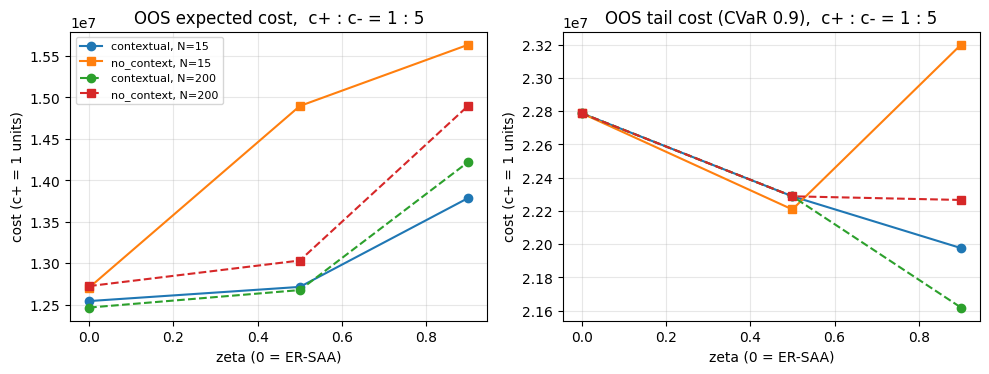

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
with open("toy_results.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(results[0].keys()))
    w.writeheader(); w.writerows(results)
print("결과 저장: toy_results.csv")

import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, key, ttl in zip(axes, ["oos", "oos_cvar90"], ["OOS expected cost", "OOS tail cost (CVaR 0.9)"]):
    for N, ls in zip(grid_N, ["-", "--"]):
        for m, mk in zip(["contextual", "no_context"], ["o", "s"]):
            ys = [r[key] for r in results if r["method"] == m and r["N"] == N and r["c_minus"] == 5.0]
            ax.plot(grid_zeta, ys, ls, marker=mk, label=f"{m}, N={N}")
    ax.set_xlabel("zeta (0 = ER-SAA)"); ax.set_ylabel("cost (c+ = 1 units)")
    ax.set_title(ttl + ",  c+ : c- = 1 : 5"); ax.grid(alpha=.3)
axes[0].legend(fontsize=8)
fig.tight_layout(); fig.savefig("toy_oos_vs_zeta.png", dpi=150); plt.show()

try:
    from google.colab import files
    files.download("toy_results.csv"); files.download("toy_oos_vs_zeta.png")
except ImportError:
    pass

## 9. f 추정 결과 점검 (EV 논문 Table 2·3, Figure 3·8에 대응)

f가 제대로 학습됐는지 네 가지를 본다.

1. **계수**: β̂₀, β̂₁이 참값(toy라서 알고 있음) 근처인가, β̂₁ > 0으로 부호가 문헌(무차량 가구 ↑ → 로보택시 선택 ↑)과 같은가.
2. **적합도**: 훈련/검정 MSE, MAE, 최대오차, R²를 p 척도로 보고 (EV 논문 Table 3 방식). 검정 자료는 참 모형에서 새로 뽑은 1,000개.
3. **가정 (2) 확인**: 잔차 평균 ≈ 0, 잔차의 퍼짐이 x에 따라 변하지 않음(등분산), 분포가 한쪽으로 치우치지 않음 → 잔차를 한 주머니에 넣어 시나리오로 재사용해도 되는지.
4. **context의 가치**: x를 쓰는 모형 vs x를 무시하고 평균 p만 쓰는 모형(no_context)의 검정 오차 비교.

그림 1의 패널: (a) 로짓 척도에서 데이터·적합선·참 직선, (b) 잔차 히스토그램, (c) 잔차 vs x, (d) 검정 자료의 예측 p vs 실제 p.

표 1. f 추정 결과 (로짓 OLS)  -- 오차 지표는 p 척도, 검정 자료 1,000개


,beta0_hat,beta1_hat,sigma_eps_hat,잔차평균,train MSE,test MSE,test MAE,test ME,test R2,no_context test MSE,no_context test R2
N,,,,,,,,,,,
15,-3.6548,1.1140,0.3246,0.0000,0.0002,0.0002,0.0101,0.0461,0.1236,0.0002,-0.0106
200,-3.4791,0.6652,0.2979,0.0000,0.0002,0.0002,0.0099,0.0479,0.1427,0.0002,-0.0126
참값,-3.5000,0.8000,0.3000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


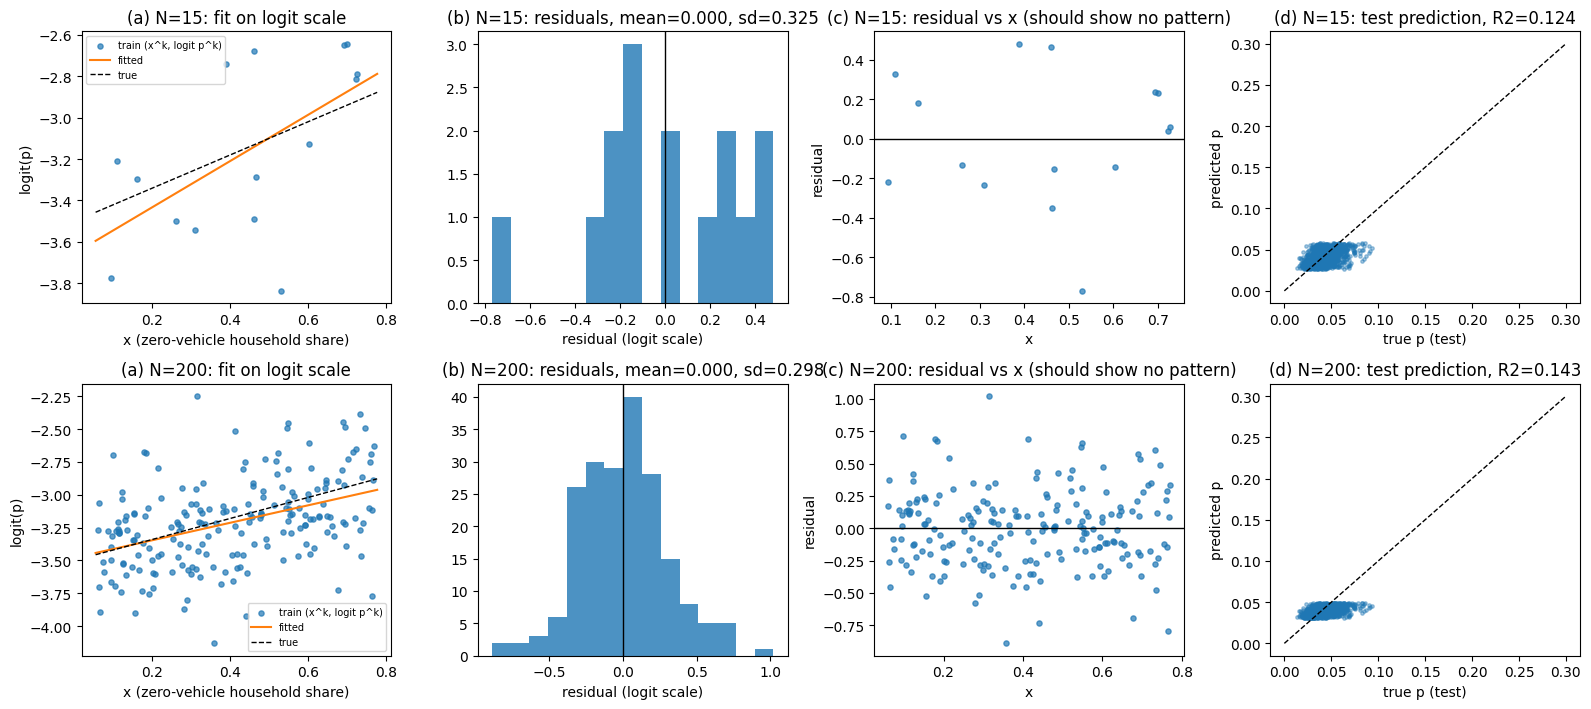

In [ ]:
# ======================================================================
# 9. f 추정 진단 (EV 논문 Table 2/3, Figure 3/8 에 대응)
# ======================================================================
# 무엇을 확인하나
#  (a) 계수: beta_hat 이 참값 근처인가 (toy 에서만 가능), 부호가 문헌과 같은가 (beta1 > 0)
#  (b) 적합도: 훈련/검정 MSE, MAE, 최대오차(ME), R^2  -- p 척도로 환산해서 보고 (EV 논문 Table 3 방식)
#  (c) 가정 (2) 확인: 잔차 평균 0, 잔차 퍼짐이 x 에 따라 변하지 않음(등분산), 한쪽으로 치우치지 않음
#  (d) context 의 가치: x 를 쓰는 모형 vs x 를 무시하고 평균 p 만 쓰는 모형의 검정 오차 비교
import pandas as pd

def regression_diagnostics(fits, N_test=1000):
    rows = []
    x_t, p_t = make_training_data(N_test, beta0, beta1, sigma_eps, x_c.min(), x_c.max())  # 검정 자료 (참 모형)
    for N, f in fits.items():
        x_k, p_k, b0, b1, eps = f["x_k"], f["p_k"], f["b0"], f["b1"], f["eps"]
        # p 척도 예측
        p_hat_tr = sigma(b0 + b1 * x_k);  p_hat_te = sigma(b0 + b1 * x_t)
        p_bar = p_k.mean()                                    # 벤치마크(no_context): 훈련 p 의 평균
        def metrics(p, ph):
            e = p - ph
            return dict(MSE=np.mean(e**2), MAE=np.mean(np.abs(e)), ME=np.max(np.abs(e)),
                        R2=1 - np.sum(e**2) / np.sum((p - p.mean())**2))
        m_tr, m_te, m_nc = metrics(p_k, p_hat_tr), metrics(p_t, p_hat_te), metrics(p_t, np.full_like(p_t, p_bar))
        rows.append({"N": N, "beta0_hat": b0, "beta1_hat": b1, "sigma_eps_hat": eps.std(),
                     "잔차평균": eps.mean(),
                     "train MSE": m_tr["MSE"], "test MSE": m_te["MSE"], "test MAE": m_te["MAE"],
                     "test ME": m_te["ME"], "test R2": m_te["R2"],
                     "no_context test MSE": m_nc["MSE"], "no_context test R2": m_nc["R2"]})
    tab = pd.DataFrame(rows).set_index("N")
    tab.loc["참값"] = [beta0, beta1, sigma_eps] + [np.nan] * (tab.shape[1] - 3)
    return tab, (x_t, p_t)

reg_table, (x_test, p_test) = regression_diagnostics(fits)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("표 1. f 추정 결과 (로짓 OLS)  -- 오차 지표는 p 척도, 검정 자료 1,000개")
display(reg_table)

# ---- 그림 1: N 별 4개 패널 ----
fig, axes = plt.subplots(len(fits), 4, figsize=(16, 3.6 * len(fits)))
xx = np.linspace(x_c.min(), x_c.max(), 100)
for r, (N, f) in enumerate(fits.items()):
    x_k, p_k, b0, b1, eps = f["x_k"], f["p_k"], f["b0"], f["b1"], f["eps"]
    z_k = logit(np.clip(p_k, 1e-3, 1 - 1e-3))
    ax = axes[r, 0]   # (a) 로짓 척도: 데이터, 적합선, 참 직선
    ax.scatter(x_k, z_k, s=14, alpha=.7, label="train (x^k, logit p^k)")
    ax.plot(xx, b0 + b1 * xx, "C1", label="fitted")
    ax.plot(xx, beta0 + beta1 * xx, "k--", lw=1, label="true")
    ax.set_xlabel("x (zero-vehicle household share)"); ax.set_ylabel("logit(p)"); ax.set_title(f"(a) N={N}: fit on logit scale"); ax.legend(fontsize=7)
    ax = axes[r, 1]   # (b) 잔차 히스토그램
    ax.hist(eps, bins=15, color="C0", alpha=.8); ax.axvline(0, color="k", lw=1)
    ax.set_xlabel("residual (logit scale)"); ax.set_title(f"(b) N={N}: residuals, mean={eps.mean():.3f}, sd={eps.std():.3f}")
    ax = axes[r, 2]   # (c) 잔차 vs x  (등분산·평균0 확인)
    ax.scatter(x_k, eps, s=14, alpha=.7); ax.axhline(0, color="k", lw=1)
    ax.set_xlabel("x"); ax.set_ylabel("residual"); ax.set_title(f"(c) N={N}: residual vs x (should show no pattern)")
    ax = axes[r, 3]   # (d) 검정: 예측 p vs 실제 p
    ax.scatter(p_test, sigma(b0 + b1 * x_test), s=6, alpha=.4)
    lim = [0, max(p_test.max(), 0.3)]; ax.plot(lim, lim, "k--", lw=1)
    ax.set_xlabel("true p (test)"); ax.set_ylabel("predicted p"); ax.set_title(f"(d) N={N}: test prediction, R2={reg_table.loc[N,'test R2']:.3f}")
fig.tight_layout(); fig.savefig("fig1_f_diagnostics.png", dpi=150); plt.show()

## 10. 전체 결과 표 (EV 논문 Table 4·8에 대응)

표 2의 한 행 = 설정 (N, c⁻, ζ) 하나. 그 설정으로 contextual 모형이 고른 진입 도시와 총 차량, in-sample 목적값, 그리고 그 해를 참 모형의 1,000개 시나리오로 채점한 OOS 평균·꼬리비용. 오른쪽 세 열은 같은 설정에서 context를 쓰지 않은 벤치마크와 그 대비 이득(%).

표 3은 변형 (5): 진입 도시 수 B를 2, 3, 5로 제한했을 때의 2단계 비용과 선택된 도시.

In [ ]:
# ======================================================================
# 10. 전체 결과 표 (EV 논문 Table 4/8 에 대응)
# ======================================================================
df = pd.DataFrame(results)
df["cities"] = df["cities"].apply(lambda L: ", ".join(L))
main_df = df[df["method"].isin(["contextual", "no_context"])]
main_df = main_df.assign(zeta=main_df["zeta"].map(lambda z: f"{z:.1f}"), c_minus=main_df["c_minus"].map(lambda v: f"{v:g}"))
ctx = main_df[main_df.method == "contextual"].set_index(["N", "c_minus", "zeta"])
noc = main_df[main_df.method == "no_context"].set_index(["N", "c_minus", "zeta"])
table2 = pd.DataFrame({
    "진입 도시 (contextual)": ctx["cities"],
    "진입 수": ctx["cities"].str.count(",") + 1,
    "Σq": ctx["total_q"],
    "in-sample": ctx["in_sample"],
    "OOS 평균": ctx["oos"],
    "OOS 꼬리(CVaR.9)": ctx["oos_cvar90"],
    "no_context OOS 평균": noc["oos"],
    "no_context OOS 꼬리": noc["oos_cvar90"],
})
table2["context 이득 (%)"] = 100 * (table2["no_context OOS 평균"] - table2["OOS 평균"]) / table2["no_context OOS 평균"]
pd.set_option("display.float_format", lambda v: f"{v:,.0f}"); pd.set_option("display.max_colwidth", 70); pd.set_option("display.width", 250)
print("표 2. 전체 결과: 설정별 최적 진입·배분과 in-sample / out-of-sample 비용 (c+ = 1 단위)")
display(table2)

bud = df[df["method"].str.startswith("budget")].copy()
bud["B"] = bud["method"].str.extract(r"(\d+)").astype(int)
table3 = bud.pivot_table(index=["N", "c_minus"], columns="B", values="oos")
table3_cities = bud.pivot_table(index=["N", "c_minus"], columns="B", values="cities", aggfunc="first")
print("\n표 3. 변형 (5): 진입 도시 수 B 별 OOS 2단계 비용 (ζ = 0.5)"); display(table3)
print("표 3-b. B 별 진입 도시"); display(table3_cities)
table2.to_csv("table2_main_results.csv", encoding="utf-8-sig"); table3.to_csv("table3_budget.csv", encoding="utf-8-sig")

표 2. 전체 결과: 설정별 최적 진입·배분과 in-sample / out-of-sample 비용 (c+ = 1 단위)


진입 도시 (contextual)  진입 수   Σq  in-sample     OOS 평균  OOS 꼬리(CVaR.9)  no_context OOS 평균  no_context OOS 꼬리  context 이득 (%)
N   c_minus zeta                                                                                                                                                                              
15  1       0.0   Chicago, Detroit, New York, Philadelphia, Pittsburgh, Sacramento, ...     9  267  2,490,926  2,695,476       4,857,473          2,758,361          4,657,473               2
            0.5            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267  2,864,469  2,724,601       4,557,473          3,112,997          4,357,473              12
            0.9                                   Chicago, New York, San Diego, Seattle     4  267  3,460,840  3,147,884       4,410,069          3,869,252          4,739,552              19
    5       0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267 11,386,313 12,541,832      22,787,364         12,702,986         22,787,364               1
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle     5  267 13,635,159 12,712,913      22,287,364         14,896,198         22,208,291              15
            0.9                                Chicago, New York, Philadelphia, Seattle     4  267 17,304,198 13,787,444      21,975,797         15,636,705         23,199,859              12
    10      0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267 22,412,124 24,728,335      45,574,729         25,166,440         45,574,729               2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle     5  267 27,186,803 25,027,407      44,574,729         28,863,429         44,263,095              13
            0.9                             Chicago, New York, San Diego, Washington DC     4  267 34,608,397 27,416,340      43,920,442         30,089,296         45,739,579               9
200 1       0.0   Chicago, Detroit, New York, Philadelphia, Pittsburgh, Sacramento, ...     8  267  2,599,840  2,662,764       4,757,473          2,748,503          4,657,473               3
            0.5            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267  3,054,078  2,712,652       4,557,473          2,980,460          4,457,473               9
            0.9                                   Chicago, New York, San Diego, Seattle     4  267  4,415,710  3,084,216       4,357,473          3,727,040          4,610,719              17
    5       0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267 12,225,772 12,463,377      22,787,364         12,722,661         22,787,364               2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle     5  267 14,870,099 12,674,534      22,287,364         13,031,319         22,287,364               3
            0.9                                            Chicago, New York, San Diego     3  267 22,045,780 14,222,971      21,617,923         14,901,907         22,265,378               5
    10      0.0            Chicago, Detroit, New York, Philadelphia, San Diego, Seattle     6  267 24,168,288 24,654,132      45,574,729         25,128,612         45,574,729               2
            0.5                     Chicago, New York, Philadelphia, San Diego, Seattle     5  267 29,646,948 24,957,044      44,574,729         25,611,150         44,574,729               3
            0.9                                            Chicago, New York, San Diego     3  267 44,013,689 27,629,179      43,180,752         28,889,111         44,519,917               4


표 3. 변형 (5): 진입 도시 수 B 별 OOS 2단계 비용 (ζ = 0.5)


B                    2          3          5
N   c_minus                                 
15  1        3,315,579  3,084,918  2,358,358
    5       14,339,887 12,668,561 10,305,798
    10      28,111,826 24,631,627 20,068,402
200 1        3,395,462  3,198,004  2,440,092
    5       14,572,482 12,726,413 11,735,447
    10      28,274,685 24,625,772 22,821,183

표 3-b. B 별 진입 도시


B                            2                             3                                                    5
N   c_minus                                                                                                      
15  1        Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
    5        Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
    10       Chicago, New York  Chicago, New York, San Diego  Chicago, New York, Philadelphia, San Diego, Seattle
200 1        Chicago, New York  Chicago, New York, San Diego  Chicago, Detroit, New York, Philadelphia, San Diego
    5        Chicago, New York  Chicago, New York, San Diego  Chicago, Philadelphia, Pittsburgh, San Diego, Tampa
    10       Chicago, New York  Chicago, New York, San Diego  Chicago, Philadelphia, Pittsburgh, San Diego, Tampa

## 11. 민감도 분석 (EV 논문 Figure 6·7에 대응)

기준 설정 N = 200, c⁻ = 5, c⁺ = 1, ζ = 0.5에서 파라미터를 **하나씩** 바꾸며 OOS 기대비용을 본다. 선 세 개: contextual ER-DRO(ζ = 0.5), contextual ER-SAA(ζ = 0), no_context.

패널: F0(진입비), Q 비율(총 차량), q̄(도시 상한), κ(대당 처리량), c⁻(c⁺ = 1 고정), β₁(context가 수요를 얼마나 좌우하는지 — EV 논문의 α₁ sweep에 대응; 참 모형이 바뀌므로 훈련·추정을 다시 함), σ_ε(수요 변동성), N(훈련 표본 수), ζ(평균 vs 꼬리 교환).

실행 시간 약 15분 (solve 약 130회).

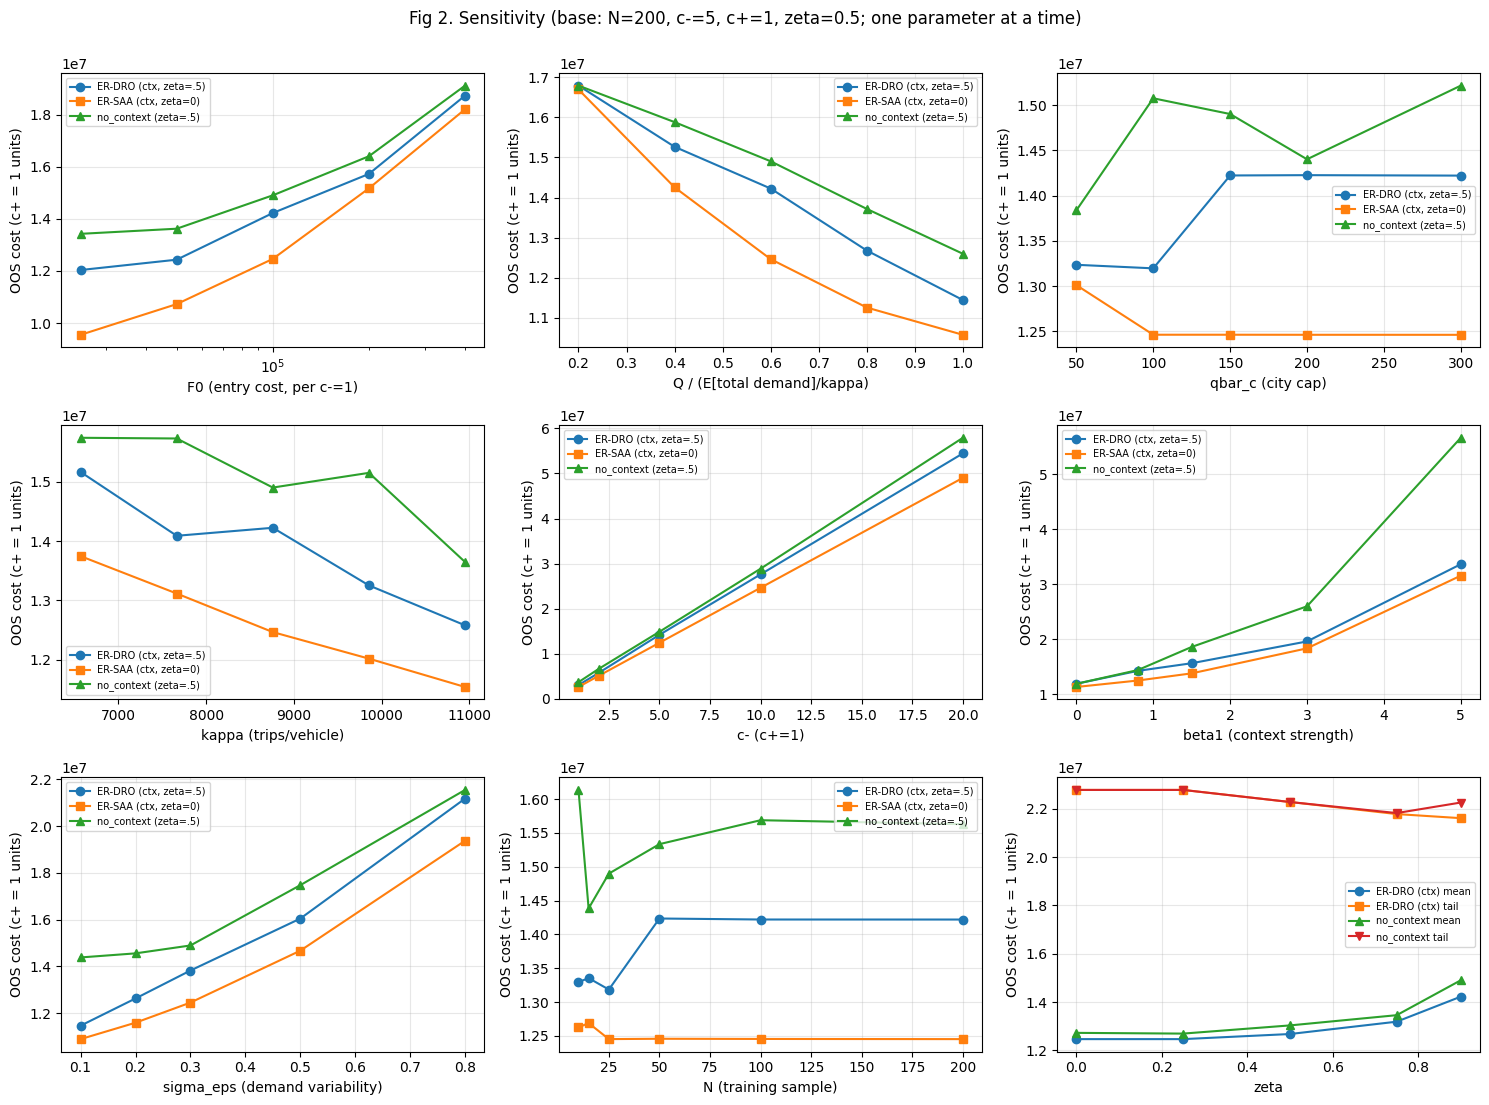

표 4. 민감도 분석 수치 (table4_sensitivity.csv 로 저장)


,parameter,value,"ER-DRO (ctx, zeta=.5)","ER-SAA (ctx, zeta=0)",no_context (zeta=.5),ER-DRO (ctx) mean,ER-DRO (ctx) tail,no_context mean,no_context tail
0,"F0 (entry cost, per c-=1)","25,000","12,035,919","9,550,795","13,424,780",NaN,NaN,NaN,NaN
1,"F0 (entry cost, per c-=1)","50,000","12,432,800","10,729,102","13,620,842",NaN,NaN,NaN,NaN
2,"F0 (entry cost, per c-=1)","100,000","14,222,971","12,463,377","14,901,907",NaN,NaN,NaN,NaN
3,"F0 (entry cost, per c-=1)","200,000","15,722,971","15,169,052","16,400,447",NaN,NaN,NaN,NaN
4,"F0 (entry cost, per c-=1)","400,000","18,726,628","18,202,394","19,109,450",NaN,NaN,NaN,NaN
5,Q / (E[total demand]/kappa),0,"16,787,334","16,691,233","16,787,334",NaN,NaN,NaN,NaN
6,Q / (E[total demand]/kappa),0,"15,263,211","14,253,088","15,878,123",NaN,NaN,NaN,NaN
7,Q / (E[total demand]/kappa),1,"14,222,971","12,463,377","14,901,907",NaN,NaN,NaN,NaN
8,Q / (E[total demand]/kappa),1,"12,678,733","11,258,250","13,715,388",NaN,NaN,NaN,NaN
9,Q / (E[total demand]/kappa),1,"11,445,299","10,578,821","12,597,833",NaN,NaN,NaN,NaN


In [ ]:
# ======================================================================
# 11. 민감도 분석 (EV 논문 Figure 6, 7 에 대응)
# ======================================================================
# 기준 설정: N = 200, c- = 5 (c+ = 1), zeta = 0.9.  파라미터 하나씩 바꾸며 OOS 기대비용을 비교
#   선: contextual ER-DRO(zeta=.5), contextual ER-SAA(zeta=0), no_context(zeta=.5)
def run_three(D_cs, D_noc, D_ev, F_c, kap, qb, Qv, cp, cm, zeta=0.9):
    out = {}
    y, q, _, _ = solve_ER_DRO(D_cs, F_c, kap, qb, Qv, cp, cm, zeta);  out["ER-DRO (ctx, zeta=.9)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    y, q, _, _ = solve_ER_DRO(D_cs, F_c, kap, qb, Qv, cp, cm, 0.0);   out["ER-SAA (ctx, zeta=0)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    y, q, _, _ = solve_ER_DRO(D_noc, F_c, kap, qb, Qv, cp, cm, zeta); out["no_context (zeta=.9)"] = oos_cost(y, q, D_ev, F_c, kap, cp, cm)[0]
    return out

base = dict(N=200, c_minus=5.0, zeta=0.9)
fb = fits[base["N"]]
sens = {}

# (a) 진입 고정비 F0
sens["F0 (entry cost, per c-=1)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, np.full(nC, v) * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
                          for v in [0.25e5, 0.5e5, 1e5, 2e5, 4e5]}
# (b) 총 차량 Q 비율 (평균 총수요 대비)
sens["Q / (E[total demand]/kappa)"] = {r: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], kappa_c, qbar_c,
                                      int(r * expected_total_demand / kappa_c[0]), c_plus, base["c_minus"])
                           for r in [0.2, 0.4, 0.6, 0.8, 1.0]}
# (c) 도시별 상한 q̄
sens["qbar_c (city cap)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], kappa_c, np.full(nC, v), Q, c_plus, base["c_minus"])
               for v in [50, 100, 150, 200, 300]}
# (d) 차량 생산성 κ (±25%)
sens["kappa (trips/vehicle)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * base["c_minus"], np.full(nC, v), qbar_c, Q, c_plus, base["c_minus"])
             for v in [6570, 7665, 8760, 9855, 10950]}
# (e) c- (c+ = 1 고정)
sens["c- (c+=1)"] = {v: run_three(fb["D_cs"], fb["D_nocontext"], D_eval, F0_c * v, kappa_c, qbar_c, Q, c_plus, v)
                     for v in [1, 2, 5, 10, 20]}
# (f) context 의존 강도 β1  (EV 논문 α1 sweep 에 대응): 참 모형이 바뀌므로 평가 시나리오·훈련·추정을 다시 함
sens["beta1 (context strength)"] = {}
for b1v in [0.0, 0.8, 1.5, 3.0, 5.0]:  # 0.8 = Loa et al. 환산값
    D_ev = M_c[:, None] * sigma(beta0 + b1v * x_c[:, None] + eps_eval[None, :])
    Qv = int(0.6 * D_ev.sum(axis=0).mean() / kappa_c[0])
    xk, pk = make_training_data(base["N"], beta0, b1v, sigma_eps, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["beta1 (context strength)"][b1v] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_ev,
                                               F0_c * base["c_minus"], kappa_c, qbar_c, Qv, c_plus, base["c_minus"])
# (g) 오차 크기 σ_ε (수요 변동성)
sens["sigma_eps (demand variability)"] = {}
for sv in [0.1, 0.2, 0.3, 0.5, 0.8]:
    D_ev = M_c[:, None] * sigma(beta0 + beta1 * x_c[:, None] + (eps_eval / sigma_eps * sv)[None, :])
    xk, pk = make_training_data(base["N"], beta0, beta1, sv, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["sigma_eps (demand variability)"][sv] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_ev,
                                      F0_c * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
# (h) 훈련 표본 수 N (DRO 의 가치가 N 에 따라 어떻게 변하나)
sens["N (training sample)"] = {}
for Nv in [10, 15, 25, 50, 100, 200]:
    xk, pk = make_training_data(Nv, beta0, beta1, sigma_eps, x_c.min(), x_c.max())
    b0h, b1h, eh = fit_logit_ols(xk, pk)
    sens["N (training sample)"][Nv] = run_three(make_scenarios(x_c, M_c, b0h, b1h, eh), M_c[:, None] * pk[None, :], D_eval,
                                       F0_c * base["c_minus"], kappa_c, qbar_c, Q, c_plus, base["c_minus"])
# (i) ζ
sens["zeta"] = {}
for zv in [0.0, 0.25, 0.5, 0.75, 0.9]:
    o = {}
    y, q, _, _ = solve_ER_DRO(fb["D_cs"], F0_c * 5, kappa_c, qbar_c, Q, c_plus, 5.0, zv); m, t = oos_cost(y, q, D_eval, F0_c * 5, kappa_c, c_plus, 5.0)
    o["ER-DRO (ctx) mean"] = m; o["ER-DRO (ctx) tail"] = t
    y, q, _, _ = solve_ER_DRO(fb["D_nocontext"], F0_c * 5, kappa_c, qbar_c, Q, c_plus, 5.0, zv); m, t = oos_cost(y, q, D_eval, F0_c * 5, kappa_c, c_plus, 5.0)
    o["no_context mean"] = m; o["no_context tail"] = t
    sens["zeta"][zv] = o

# ---- 그림 2: 3 x 3 패널 ----
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
for ax, (pname, d) in zip(axes.ravel(), sens.items()):
    xs = list(d.keys()); keys = list(next(iter(d.values())).keys())
    for kname, mk in zip(keys, ["o", "s", "^", "v"]):
        ax.plot(xs, [d[x][kname] for x in xs], marker=mk, label=kname)
    ax.set_xlabel(pname); ax.set_ylabel("OOS cost (c+ = 1 units)"); ax.grid(alpha=.3); ax.legend(fontsize=7)
    if pname.startswith("F0"): ax.set_xscale("log")
fig.suptitle("Fig 2. Sensitivity (base: N=200, c-=5, c+=1, zeta=0.9; one parameter at a time)", y=1.0)
fig.tight_layout(); fig.savefig("fig2_sensitivity.png", dpi=150); plt.show()

# ---- 표 4: 민감도 수치 ----
sens_rows = [dict(parameter=p, value=v, **o) for p, d in sens.items() for v, o in d.items()]
sens_df = pd.DataFrame(sens_rows); sens_df.to_csv("table4_sensitivity.csv", index=False, encoding="utf-8-sig")
print("표 4. 민감도 분석 수치 (table4_sensitivity.csv 로 저장)"); display(sens_df)